In [1]:
import pandas as pd

# read the dataset

In [76]:
movies= pd.read_csv(r'C:\Users\Admin\Downloads\archive\movie.csv')

In [77]:
movies.shape

(27278, 3)

In [4]:
ratings=pd.read_csv(r'C:\Users\Admin\Downloads\archive\rating.csv')

In [6]:
ratings.shape

(20000263, 4)

In [8]:
tags=pd.read_csv(r'C:\Users\Admin\Downloads\archive\tag.csv')

In [9]:
tags.shape

(465564, 4)

# data analysis

In [10]:
print(movies.columns)
print(tags.columns)
print(ratings.columns)

Index(['movieId', 'title', 'genres'], dtype='str')
Index(['userId', 'movieId', 'tag', 'timestamp'], dtype='str')
Index(['userId', 'movieId', 'rating', 'timestamp'], dtype='str')


#  For current analysis, we will remove timestamp

In [11]:
del ratings['timestamp']
del tags['timestamp']

In [12]:
print(movies.columns)
print(tags.columns)
print(ratings.columns)

Index(['movieId', 'title', 'genres'], dtype='str')
Index(['userId', 'movieId', 'tag'], dtype='str')
Index(['userId', 'movieId', 'rating'], dtype='str')


#  Data Structures:

In [84]:
tags.head(1)
print(type(tags.head(1)))
print(tags.head(1))

<class 'pandas.DataFrame'>
   userId  movieId          tag
0      18     4141  Mark Waters


In [81]:
row_0 = tags.iloc[0]
type(row_0)

pandas.Series

In [16]:
print(row_0)

userId              18
movieId           4141
tag        Mark Waters
Name: 0, dtype: object


In [17]:
row_0.index

Index(['userId', 'movieId', 'tag'], dtype='str')

In [85]:
row_0['userId']

np.int64(18)

In [90]:
'rating' in row_0

False

In [93]:
row_0.name

np.int64(0)

In [96]:
row_0 = row_0.rename('firstRow')
row_0.name

'firstRow'

In [94]:
print(row_0)

userId              18
movieId           4141
tag        Mark Waters
Name: 0, dtype: object


# DataFrames

In [97]:
tags.head()

,userId,movieId,tag
0,18,4141,Mark Waters
1,65,208,dark hero
2,65,353,dark hero
3,65,521,noir thriller
4,65,592,dark hero


In [23]:
tags.index

RangeIndex(start=0, stop=465564, step=1)

In [24]:
tags.columns

Index(['userId', 'movieId', 'tag'], dtype='str')

In [98]:
tags.iloc[0,11,500] 

IndexingError: Too many indexers

In [99]:
tags.iloc[ [0,11,500,600] ]

,userId,movieId,tag
0,18,4141,Mark Waters
11,65,1783,noir thriller
500,342,55908,entirely dialogue
600,348,608,black comedy


# Descriptive Statistics 
Let's look how the ratings are distributed!

In [26]:
ratings['rating'].describe()

count    2.000026e+07
mean     3.525529e+00
std      1.051989e+00
min      5.000000e-01
25%      3.000000e+00
50%      3.500000e+00
75%      4.000000e+00
max      5.000000e+00
Name: rating, dtype: float64

In [30]:
ratings['rating'].mean()

np.float64(3.5255285642993797)

In [31]:
ratings.mean()

userId     69045.872583
movieId     9041.567330
rating         3.525529
dtype: float64

In [33]:
ratings['rating'].min()

np.float64(0.5)

In [34]:
ratings['rating'].max()

np.float64(5.0)

In [35]:
ratings['rating'].std()

np.float64(1.0519889192942418)

In [36]:
ratings['rating'].mode()

0    4.0
Name: rating, dtype: float64

In [37]:
ratings.corr()

,userId,movieId,rating
userId,1.000000,-0.000850,0.001175
movieId,-0.000850,1.000000,0.002606
rating,0.001175,0.002606,1.000000


In [104]:
filter1 = ratings['rating'] > 3
print(filter1)
filter1.any()

0            True
1            True
2            True
3            True
4            True
            ...  
20000258     True
20000259     True
20000260    False
20000261     True
20000262    False
Name: rating, Length: 20000263, dtype: bool


np.True_

In [39]:
filter2 = ratings['rating'] > 0
filter2.all()

np.True_

#  Data Cleaning: Handling Missing Data

In [40]:
movies.shape

(27278, 3)

In [105]:
movies.isnull().any().any()

np.False_

In [ ]:
* Thats nice ! No NULL values !

In [43]:
ratings.shape

(20000263, 3)

In [44]:
ratings.isnull().any().any()

np.False_

In [ ]:
* Thats nice ! No NULL values !

In [45]:
tags.shape

(465564, 3)

In [47]:
tags.isnull().any().any()

np.True_

In [ ]:
* We have some tags which are NULL.

In [49]:
tags=tags.dropna()

In [50]:
tags.isnull().any().any()

np.False_

In [51]:
tags.shape

(465548, 3)

In [ ]:
* Thats nice ! No NULL values ! Notice the number of lines have reduced.

#  Data Visualization

array([[<Axes: title={'center': 'rating'}>]], dtype=object)

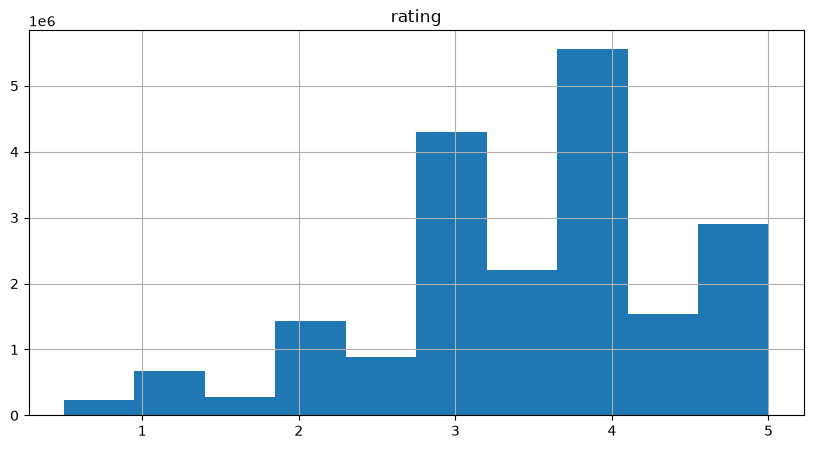

In [52]:
%matplotlib inline

ratings.hist(column='rating', figsize=(10,5))

<Axes: >

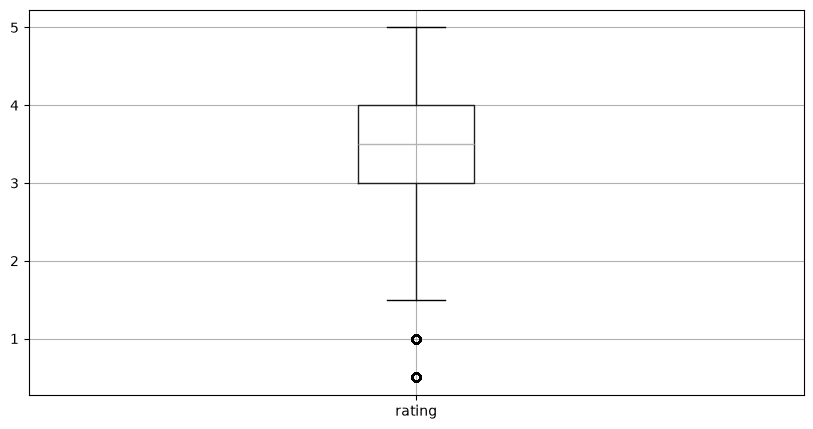

In [53]:
ratings.boxplot(column='rating', figsize=(10,5))

# Slicing Out Columns

In [54]:
tags['tag'].head()

0      Mark Waters
1        dark hero
2        dark hero
3    noir thriller
4        dark hero
Name: tag, dtype: str

In [55]:
movies[['title','genres']].head()

,title,genres
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,Jumanji (1995),Adventure|Children|Fantasy
2,Grumpier Old Men (1995),Comedy|Romance
3,Waiting to Exhale (1995),Comedy|Drama|Romance
4,Father of the Bride Part II (1995),Comedy


In [56]:
ratings[-10:]

,userId,movieId,rating
20000253,138493,60816,4.5
20000254,138493,61160,4.0
20000255,138493,65682,4.5
20000256,138493,66762,4.5
20000257,138493,68319,4.5
20000258,138493,68954,4.5
20000259,138493,69526,4.5
20000260,138493,69644,3.0
20000261,138493,70286,5.0
20000262,138493,71619,2.5


In [57]:
tag_counts = tags['tag'].value_counts()
tag_counts[-10:]

tag
Roland JoffÃ©                                                           1
Seu Jorge                                                               1
Michel Audiard                                                          1
French film                                                             1
Clouseau                                                                1
Disguises                                                               1
retarted                                                                1
circle k                                                                1
This movie should have been called \\"How Cocaine Ruined Disney\"\""    1
topless scene                                                           1
Name: count, dtype: int64

<Axes: xlabel='tag'>

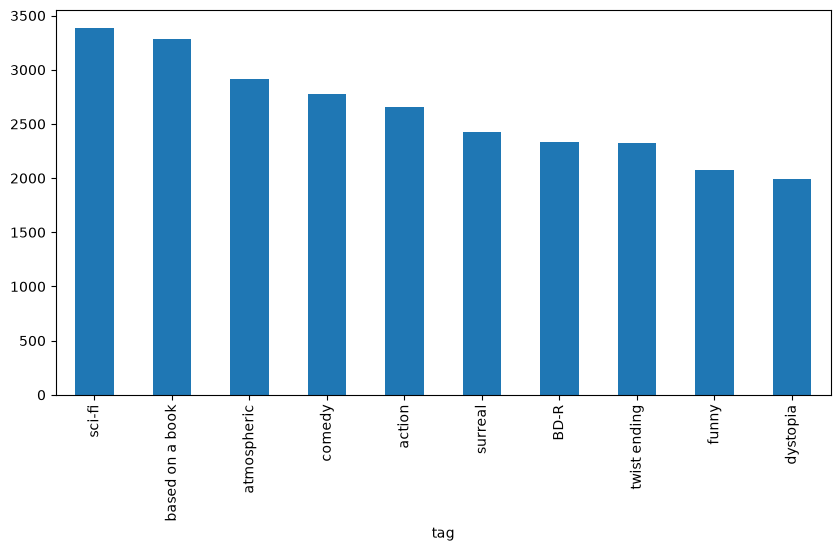

In [58]:
tag_counts[:10].plot(kind='bar', figsize=(10,5))

#  Filters for Selecting Rows

In [59]:
is_highly_rated = ratings['rating'] >= 5.0
ratings[is_highly_rated][30:50]

,userId,movieId,rating
239,3,50,5.0
242,3,175,5.0
244,3,223,5.0
245,3,260,5.0
246,3,316,5.0
247,3,318,5.0
248,3,329,5.0
252,3,457,5.0
253,3,480,5.0
254,3,490,5.0


In [60]:
is_action= movies['genres'].str.contains('Action')
movies[is_action][5:15]

,movieId,title,genres
22,23,Assassins (1995),Action|Crime|Thriller
41,42,Dead Presidents (1995),Action|Crime|Drama
43,44,Mortal Kombat (1995),Action|Adventure|Fantasy
50,51,Guardian Angel (1994),Action|Drama|Thriller
65,66,Lawnmower Man 2: Beyond Cyberspace (1996),Action|Sci-Fi|Thriller
69,70,From Dusk Till Dawn (1996),Action|Comedy|Horror|Thriller
70,71,Fair Game (1995),Action
75,76,Screamers (1995),Action|Sci-Fi|Thriller
77,78,"Crossing Guard, The (1995)",Action|Crime|Drama|Thriller
85,86,White Squall (1996),Action|Adventure|Drama


In [61]:
movies[is_action].head(15)

,movieId,title,genres
5,6,Heat (1995),Action|Crime|Thriller
8,9,Sudden Death (1995),Action
9,10,GoldenEye (1995),Action|Adventure|Thriller
14,15,Cutthroat Island (1995),Action|Adventure|Romance
19,20,Money Train (1995),Action|Comedy|Crime|Drama|Thriller
22,23,Assassins (1995),Action|Crime|Thriller
41,42,Dead Presidents (1995),Action|Crime|Drama
43,44,Mortal Kombat (1995),Action|Adventure|Fantasy
50,51,Guardian Angel (1994),Action|Drama|Thriller
65,66,Lawnmower Man 2: Beyond Cyberspace (1996),Action|Sci-Fi|Thriller


#  Group By and Aggregate

In [62]:
ratings_count = ratings[['movieId','rating']].groupby('rating').count()
ratings_count

,movieId
rating,
0.5,239125
1.0,680732
1.5,279252
2.0,1430997
2.5,883398
3.0,4291193
3.5,2200156
4.0,5561926
4.5,1534824


In [63]:
average_rating = ratings[['movieId','rating']].groupby('movieId').mean()
average_rating.head()

,rating
movieId,
1,3.921240
2,3.211977
3,3.151040
4,2.861393
5,3.064592


In [64]:
movie_count = ratings[['movieId','rating']].groupby('movieId').count()
movie_count.head()

,rating
movieId,
1,49695
2,22243
3,12735
4,2756
5,12161


In [65]:
movie_count = ratings[['movieId','rating']].groupby('movieId').count()
movie_count.tail()

,rating
movieId,
131254,1
131256,1
131258,1
131260,1
131262,1


# Merge Dataframes

In [66]:
tags.head()

,userId,movieId,tag
0,18,4141,Mark Waters
1,65,208,dark hero
2,65,353,dark hero
3,65,521,noir thriller
4,65,592,dark hero


In [67]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [68]:
t = movies.merge(tags, on='movieId', how='inner')
t.head()

,movieId,title,genres,userId,tag
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1644,Watched
1,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1741,computer animation
2,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1741,Disney animated feature
3,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1741,Pixar animation
4,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1741,TÃ©a Leoni does not star in this movie


In [ ]:
* More examples: http://pandas.pydata.org/pandas-docs/stable/merging.html

# Combine aggreagation, merging, and filters to get useful analytics

In [69]:
avg_ratings= ratings.groupby('movieId', as_index=False).mean()
del avg_ratings['userId']
avg_ratings.head()

,movieId,rating
0,1,3.921240
1,2,3.211977
2,3,3.151040
3,4,2.861393
4,5,3.064592


In [70]:
box_office = movies.merge(avg_ratings, on='movieId', how='inner')
box_office.tail()

,movieId,title,genres,rating
26739,131254,Kein Bund für's Leben (2007),Comedy,4.0
26740,131256,"Feuer, Eis & Dosenbier (2002)",Comedy,4.0
26741,131258,The Pirates (2014),Adventure,2.5
26742,131260,Rentun Ruusu (2001),(no genres listed),3.0
26743,131262,Innocence (2014),Adventure|Fantasy|Horror,4.0


In [71]:
is_highly_rated = box_office['rating'] >= 4.0
box_office[is_highly_rated][-5:]

,movieId,title,genres,rating
26737,131250,No More School (2000),Comedy,4.0
26738,131252,Forklift Driver Klaus: The First Day on the Jo...,Comedy|Horror,4.0
26739,131254,Kein Bund für's Leben (2007),Comedy,4.0
26740,131256,"Feuer, Eis & Dosenbier (2002)",Comedy,4.0
26743,131262,Innocence (2014),Adventure|Fantasy|Horror,4.0


In [72]:
is_Adventure = box_office['genres'].str.contains('Adventure')
box_office[is_Adventure][:5]

,movieId,title,genres,rating
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,3.921240
1,2,Jumanji (1995),Adventure|Children|Fantasy,3.211977
7,8,Tom and Huck (1995),Adventure|Children,3.142049
9,10,GoldenEye (1995),Action|Adventure|Thriller,3.430029
12,13,Balto (1995),Adventure|Animation|Children,3.272416


In [73]:
box_office[is_Adventure & is_highly_rated][-5:]

,movieId,title,genres,rating
26611,130586,Itinerary of a Spoiled Child (1988),Adventure|Drama,4.5
26655,130996,The Beautiful Story (1992),Adventure|Drama|Fantasy,5.0
26667,131050,Stargate SG-1 Children of the Gods - Final Cut...,Adventure|Sci-Fi|Thriller,5.0
26736,131248,Brother Bear 2 (2006),Adventure|Animation|Children|Comedy|Fantasy,4.0
26743,131262,Innocence (2014),Adventure|Fantasy|Horror,4.0


# Vectorized String Operations

In [74]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


# Split 'genres' into multiple columns 

In [75]:
movie_genres = movies['genres'].str.split('|', expand=True)

In [ ]:
0.
























































































































































































    -